# Experiment 5: Air Track III — Conservation of Energy
**Team name:** Team Rocket
**Team members:** Josh, Alivia, Aston, Lucas  
**Lab dates:** October 26 and November 2, 2026  
**Due:** November 2 at 8:45 p.m.

## Objectives
Measure a spring constant, compare gravitational and elastic potential energies with measured kinetic energies, propagate measurement uncertainties, and assess the mechanical-energy model.

Open this notebook from your **team fork** in Colab after **Sync fork → Update branch**. Run each data cell immediately after collecting that configuration. All numerical entries below are **illustrative examples, not team measurements**. Replace every example and instrument uncertainty. Keep all raw trials.

One team notebook is submitted through Scholar. Each student separately submits a private Individual Team Effort Report through Scholar; never commit effort reports to GitHub.

# Apparatus and safety
Air track, blower, cart and flag, pulley, string (about 1.5 m), hanger and masses, one photogate, PASCO 850 interface and Capstone, balance, calipers, ruler, meter stick, spring, washer, long support rod for calibration, short rod for launching, and wooden shims for the optional incline experiment.

- Keep paper beneath the cart when the blower is off. Never slide a cart on an unpowered track.
- Secure the rubber-band bumper before launching. Catch the cart safely before a collision or rebound through the gate.
- Secure masses and keep fingers, hair, and clothing clear of the pulley and string.
- Keep the spring aligned on its support rod. Include the washer in the calibration load and **never exceed 1.1 kg** on the spring.
- **Never fully compress the spring:** the last few millimeters are nonlinear. For launch trials use compression of at least 1 cm within the measured linear range.

The [printable experiment instructions](https://github.com/brash99/phys201l/blob/main/Experiment_Instructions/Lab05_Air_Track_III_Conservation_of_Energy.pdf) provide the original apparatus reference. Record your actual setup below.

# Physical model
A photogate measures average speed during the flag's passage: $v=L/\Delta t$. A short flag better approximates instantaneous speed, but requires reliable timing.

For a level cart connected to a falling hanger, released from rest with taut string,
$$U_g=m_hgh,\qquad K_f=\tfrac12(m_c+m_h)v^2,\qquad v_{\rm pred}=\sqrt{\frac{2m_hgh}{m_c+m_h}}.$$
Here $h$ is the hanger's **vertical drop from release to the measurement position**, not its initial height above the floor. The cart and hanger have equal speed while the string remains taut. The flag must clear the gate **before** the hanger hits anything. Neglect string mass, pulley rotational energy, drag, and friction; discuss evidence for these approximations. $g$ is gravitational acceleration, not the universal gravitational constant.

For a cart launched by a spring on the level track,
$$F_{\rm load}=kx+b,\qquad U_s=\tfrac12kx_s^2,\qquad K_f=\tfrac12m_cv^2,\qquad v_{\rm pred}=x_s\sqrt{k/m_c}.$$
Measure compression from the spring's unloaded length. Calibrate with load force versus compression; its slope is $k$. A nonzero intercept can reveal a zero offset or preload. Resolve a significant offset before using $U_s=\tfrac12kx_s^2$. Measure launch speed **after** the cart has left the spring, with the hanger/string disconnected.

# Set up the track and photogate
1. Disconnect the string, turn on the blower, and level the track until the cart shows no reproducible drift.
2. Connect the photogate to a PASCO 850 digital input. In Capstone's Hardware Setup select Photogate; in Timer Setup select a preconfigured single-flag timer and speed measurement.
3. Measure the flag length, enter it in meters in Capstone, and record its uncertainty. Adjust the gate height so only the flag triggers the LED, not the string or cart body.
4. For gravity trials, align the string parallel to the track and check that the pulley turns freely. Choose a gate location allowing the entire flag to clear before the hanger reaches the floor. Mark the release and measurement positions; measure the corresponding drop.
5. For spring trials, disconnect the string and place the gate beyond the point where the cart loses contact with the spring. Keep it close enough to limit frictional loss.

**Team setup and photogate placement rationale:** REPLACE WITH YOUR DESCRIPTION AND A LABELED DIAGRAM OR PHOTO.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import P201_Functions as p201
except ImportError:
    %pip -q install P201_Functions
    import P201_Functions as p201

# REPLACE with measured instrument values and justified standard uncertainties.
flag_length = 0.01185       # m; must match the Capstone setting
u_flag_length = 0.0005     # m
u_gate_time = 0.0001       # s; justify from your timer
u_speed_resolution = 0.002 # m/s; standard uncertainty of displayed speed
# Use local gravitational acceleration, as in Lab 4.
g = 9.805                  # m/s^2
u_g = 0.005                # m/s^2
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## Uncertainty conventions
All `u_` entries are standard uncertainties. Convert instrument limits to standard uncertainties using a justified distribution. Keep significant figures in final reported values consistent with uncertainty.

The helpers report sample standard deviation $s_v$ (`ddof=1`) and standard error $s_v/\sqrt n$ separately. The uncertainty used for mean speed combines that standard error with the common flag-length calibration and a conservative instrument floor based on gate timing and speed resolution. The floor is not divided by $\sqrt n$. If timing/resolution is already represented by scatter, this can be conservative; explain your choice and avoid claiming independent information twice.

Independent input uncertainties propagate by $u_f^2=\sum_i(\partial f/\partial q_i)^2u_{q_i}^2$. Energies below use the **mean speed**, $K_f=\tfrac12M\bar v^2$. The energy difference $D=U-K_f$ is propagated directly from inputs so the common hanger mass is not counted as independent twice. Shared flag calibration, $g$, and spring constant correlate configurations; plots and fits are diagnostic, not independent statistical tests. Interpret $D/u_D$ as a descriptive discrepancy in standard-uncertainty units, not proof of conservation or a formal p-value.

In [3]:
def positive(**values):
    for name, value in values.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and positive")


def speed_summary(speeds):
    v = np.asarray(speeds, dtype=float)
    if v.ndim != 1 or len(v) < 4 or not np.all(np.isfinite(v)) or np.any(v <= 0):
        raise ValueError("Enter at least four finite, positive trial speeds")
    positive(flag_length=flag_length, u_flag_length=u_flag_length,
             u_gate_time=u_gate_time, u_speed_resolution=u_speed_resolution)
    mean = v.mean()
    sd = v.std(ddof=1)
    sem = sd / np.sqrt(len(v))
    timing_floor = mean**2 * u_gate_time / flag_length
    instrument_floor = max(timing_floor, u_speed_resolution)
    u_mean = np.sqrt(sem**2 + (mean*u_flag_length/flag_length)**2 + instrument_floor**2)
    display(pd.DataFrame({"Trial": np.arange(1, len(v)+1), "Speed (m/s)": v}))
    print(f"Mean speed = {mean:.6g} ± {u_mean:.3g} m/s; s = {sd:.3g}; SEM = {sem:.3g} m/s")
    return mean, u_mean


def gravity_run(m_cart, u_m_cart, m_hang, u_m_hang, h, u_h, speeds):
    positive(m_cart=m_cart, u_m_cart=u_m_cart, m_hang=m_hang,
             u_m_hang=u_m_hang, h=h, u_h=u_h, g=g, u_g=u_g)
    v, uv = speed_summary(speeds)
    mass = m_cart + m_hang
    u_mass = np.hypot(u_m_cart, u_m_hang)
    U = m_hang*g*h
    uU = np.sqrt((g*h*u_m_hang)**2 + (m_hang*h*u_g)**2 + (m_hang*g*u_h)**2)
    K = 0.5*mass*v**2
    uK = np.hypot(0.5*v**2*u_mass, mass*v*uv)
    pred = np.sqrt(2*U/mass)
    upred = pred/2*np.sqrt((m_cart/(m_hang*mass)*u_m_hang)**2
                          + (u_m_cart/mass)**2 + (u_g/g)**2 + (u_h/h)**2)
    uD = np.sqrt(((g*h-0.5*v**2)*u_m_hang)**2 + (0.5*v**2*u_m_cart)**2
                 + (m_hang*h*u_g)**2 + (m_hang*g*u_h)**2 + (mass*v*uv)**2)
    return {"U (J)": U, "u_U (J)": uU, "K (J)": K, "u_K (J)": uK,
            "D (J)": U-K, "u_D (J)": uD, "D/u_D": (U-K)/uD,
            "v_pred (m/s)": pred, "u_v_pred (m/s)": upred}


def spring_run(m_cart, u_m_cart, x_s, u_x_s, speeds):
    positive(m_cart=m_cart, u_m_cart=u_m_cart, x_s=x_s, u_x_s=u_x_s, k=k, u_k=u_k)
    v, uv = speed_summary(speeds)
    U = 0.5*k*x_s**2
    uU = np.hypot(0.5*x_s**2*u_k, k*x_s*u_x_s)
    K = 0.5*m_cart*v**2
    uK = np.hypot(0.5*v**2*u_m_cart, m_cart*v*uv)
    uD = np.hypot(uU, uK)
    pred = x_s*np.sqrt(k/m_cart)
    upred = pred*np.sqrt((u_x_s/x_s)**2 + (u_k/(2*k))**2 + (u_m_cart/(2*m_cart))**2)
    dynamic_k = m_cart*v**2/x_s**2
    u_dynamic_k = dynamic_k*np.sqrt((u_m_cart/m_cart)**2 + (2*uv/v)**2 + (2*u_x_s/x_s)**2)
    return {"U (J)": U, "u_U (J)": uU, "K (J)": K, "u_K (J)": uK,
            "D (J)": U-K, "u_D (J)": uD, "D/u_D": (U-K)/uD,
            "v_pred (m/s)": pred, "u_v_pred (m/s)": upred,
            "k_dynamic (N/m)": dynamic_k, "u_k_dynamic (N/m)": u_dynamic_k}


def show_result(result):
    display(pd.DataFrame([result]))


def energy_plot(results, title):
    table = pd.DataFrame(results).T
    display(table)
    plt.figure(figsize=(8, 5))
    plt.errorbar(table["U (J)"], table["K (J)"], xerr=table["u_U (J)"],
                 yerr=table["u_K (J)"], fmt="o", capsize=4, label="Measurements")
    maximum = max(table["U (J)"].max(), table["K (J)"].max())*1.1
    plt.plot([0, maximum], [0, maximum], "k--", label="Ideal: K = U")
    plt.xlabel("Initial potential energy (J)")
    plt.ylabel("Final kinetic energy (J)")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    return table

# Part I — Measure the spring constant
Place the spring on the long vertical rod so it cannot buckle; place a washer above it. Measure the unloaded spring length and then its compression for several loads over the intended launch range. Include the washer in each load mass, avoid full compression, and stay below 1.1 kg total. Repeat readings to assess scatter and check unloading for hysteresis.

Create a labeled **load force versus compression** graph in Capstone (Table & Graph → Create New → User-Entered Data, with units N and m), then reproduce and fit the measurements below. Preserve the raw mass and compression measurements, not just a fitted constant. If compression is obtained from two length readings, propagate both uncertainties; a shared unloaded-length zero introduces correlation.

The course-standard fit weights force uncertainties only. Horizontal error bars are shown but not used by this fit. Compare $k u_x$ with $u_F$: if horizontal uncertainty is material, discuss its effect with the instructor before quoting a precise $u_k$. Resolve zero/preload effects and increase the justified calibration uncertainty when needed. Do not silently treat the fitted statistical uncertainty as a complete systematic-error budget.

,Mass (kg),u_mass (kg),Compression (m),u_x (m),Force (N),u_force (N)
0,0.102,5e-05,0.0031,0.0001,1.00011,0.000707421
1,0.202,5e-05,0.0062,0.0001,1.98061,0.0011227
2,0.302,5e-05,0.0093,0.0001,2.96111,0.00158759
3,0.402,5e-05,0.0123,0.0001,3.94161,0.00206892
4,0.502,5e-05,0.0154,0.0001,4.92211,0.00255743
5,0.602,5e-05,0.0184,0.0001,5.90261,0.00304966


Spring calibration: Coefficients (from curve_fit)
[7.30292549e-03 3.19213854e+02]
Spring calibration: Covariance Matrix (from curve_fit)
[[ 8.62348250e-07 -9.88426232e-05]
 [-9.88426232e-05  1.65370819e-02]]

Spring calibration: Final Result: y = (319.21385 +/- 0.12860) x + (0.00730 +/- 0.00093)



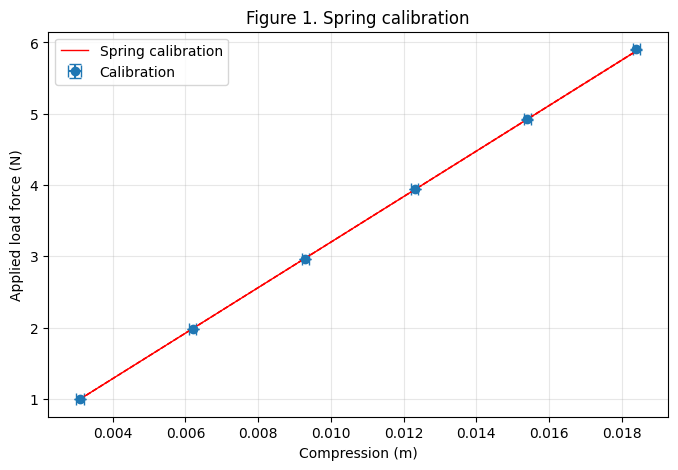

k_fit = 319.214 ± 0.129 N/m
Intercept = 0.00730293 ± 0.000929 N
Largest k*u_x / u_force: 45.123577780424135


In [ ]:
# REPLACE all calibration values with team measurements. Mass includes washer.
load_mass = np.array([0.102, 0.202, 0.302, 0.402, 0.502, 0.602]) # kg
u_load_mass = np.full(6, 0.00005) # kg
compression = np.array([0.0031, 0.0062, 0.0093, 0.0123, 0.0154, 0.0184]) # m
u_compression = np.full(6, 0.0001) # m
if not (load_mass.shape == u_load_mass.shape == compression.shape == u_compression.shape):
    raise ValueError("Calibration arrays must have matching shapes")
if len(load_mass) < 4 or np.unique(compression).size < 4:
    raise ValueError("Use at least four distinct calibration compressions")
for values in [load_mass, u_load_mass, compression, u_compression]:
    if not np.all(np.isfinite(values)) or np.any(values <= 0):
        raise ValueError("Calibration entries must be finite and positive")
if np.any(load_mass > 1.1):
    raise ValueError("Never exceed the 1.1 kg spring load limit")
force = load_mass*g
u_force = np.hypot(g*u_load_mass, load_mass*u_g)
display(pd.DataFrame({"Mass (kg)":load_mass, "u_mass (kg)":u_load_mass,
                      "Compression (m)":compression, "u_x (m)":u_compression,
                      "Force (N)":force, "u_force (N)":u_force}))
plt.figure(figsize=(8, 5))
plt.errorbar(compression, force, xerr=u_compression, yerr=u_force, fmt="o", capsize=4, label="Calibration")
b_cal, k_fit, u_b_cal, u_k_fit = p201.linear_fit_plot_errors(
    compression, force, u_force, plt, labelstring="Spring calibration")
plt.xlabel("Compression (m)")
plt.ylabel("Applied load force (N)")
plt.title("Figure 1. Spring calibration")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
positive(k_fit=k_fit, u_k_fit=u_k_fit)
print(f"k_fit = {k_fit:.6g} ± {u_k_fit:.3g} N/m")
print(f"Intercept = {b_cal:.6g} ± {u_b_cal:.3g} N")
print("Largest k*u_x / u_force:", np.max(k_fit*u_compression/u_force))

In [ ]:
# REPLACE with a justified additional calibration uncertainty budget, if needed.
# Example allowance illustrates horizontal-reading and calibration effects.
u_k_additional = 3.0 # N/m; discuss and justify, do not copy automatically
if not np.isfinite(u_k_additional) or u_k_additional < 0:
    raise ValueError("Additional calibration uncertainty must be finite and nonnegative")
k = k_fit
u_k = np.hypot(u_k_fit, u_k_additional)
print(f"Spring constant used for energies: {k:.6g} ± {u_k:.3g} N/m")

Spring constant used for energies: 319.214 ± 3 N/m


**Calibration checkpoint:** REPLACE WITH YOUR interpretation of linearity, intercept, compression uncertainty, repeatability/hysteresis, usable compression range, and the uncertainty budget adopted for k. Resolve issues before launch trials.

# Part II — Gravitational potential energy to kinetic energy
For each of **four different hanging-mass configurations**, measure total moving cart mass (including flag and attachments), total hanger mass, and vertical drop to the gate position. Release from rest without pushing. Collect **four trials per configuration**. Keep the string taut throughout flag passage. Run the corresponding cell and inspect its table before changing the apparatus.

Use a safe gate location, not a measurement after the hanger strikes the floor. A finite flag averages speed while the cart accelerates; describe how you made this approximation reasonable and how you defined the drop at the measurement position.

## Gravity configuration 1
Collect four trials, enter them, run the cell, and check the result before changing the hanging mass.

In [4]:
# REPLACE every example with measurements for configuration 1.
m_cart = 0.18995      # kg; all moving cart attachments included
u_m_cart = 0.000005   # kg
m_hang = 0.0099       # kg; hanger + all added masses
u_m_hang = 0.000005   # kg
h = 0.866              # m; drop from release to gate measurement position
u_h = 0.0005         # m
speeds = [0.99, 0.99, 0.99, 0.99]         # m/s; preserve trial order
gravity_1 = gravity_run(m_cart, u_m_cart, m_hang, u_m_hang, h, u_h, speeds)
show_result(gravity_1)

,Trial,Speed (m/s)
0,1,0.99
1,2,0.99
2,3,0.99
3,4,0.99


Mean speed = 0.99 ± 0.0426 m/s; s = 0; SEM = 0 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s)
0,0.0840622,7.74318e-05,0.0979365,0.00842513,-0.0138743,0.00842547,-1.64671,0.917198,0.000416405


## Gravity configuration 2
Collect four trials, enter them, run the cell, and check the result before changing the hanging mass.

In [11]:
# REPLACE every example with measurements for configuration 2.
m_cart = 0.18995      # kg; all moving cart attachments included
u_m_cart = 0.000005   # kg
m_hang = 0.00485        # kg; hanger + all added masses
u_m_hang = 0.000005   # kg
h = 0.833             # m; drop from release to gate measurement position
u_h = 0.0005         # m
speeds = [0.68, 0.68, 0.68, 0.68]         # m/s; preserve trial order
gravity_2 = gravity_run(m_cart, u_m_cart, m_hang, u_m_hang, h, u_h, speeds)
show_result(gravity_2)

,Trial,Speed (m/s)
0,1,0.68
1,2,0.68
2,3,0.68
3,4,0.68


Mean speed = 0.68 ± 0.029 m/s; s = 0; SEM = 0 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s)
0,0.0396127,5.13919e-05,0.0450378,0.00383564,-0.00542507,0.00383597,-1.41426,0.637731,0.000407292


## Gravity configuration 3
Collect four trials, enter them, run the cell, and check the result before changing the hanging mass.

In [12]:
# REPLACE every example with measurements for configuration 3.
m_cart = 0.18995      # kg; all moving cart attachments included
u_m_cart = 0.000005   # kg
m_hang = 0.01477        # kg; hanger + all added masses
u_m_hang = 0.000005   # kg
h = 0.833              # m; drop from release to gate measurement position
u_h = 0.0005         # m
speeds = [1.16,1.17, 1.17, 1.16]         # m/s; preserve trial order
gravity_3 = gravity_run(m_cart, u_m_cart, m_hang, u_m_hang, h, u_h, speeds)
show_result(gravity_3)

,Trial,Speed (m/s)
0,1,1.16
1,2,1.17
2,3,1.17
3,4,1.16


Mean speed = 1.165 ± 0.0506 m/s; s = 0.00577; SEM = 0.00289 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s)
0,0.120635,0.000103418,0.138926,0.0120574,-0.0182906,0.0120578,-1.51691,1.0856,0.00046045


## Gravity configuration 4
Collect four trials, enter them, run the cell, and check the result before changing the hanging mass.

In [13]:
# REPLACE every example with measurements for configuration 4.
m_cart = 0.18995      # kg; all moving cart attachments included
u_m_cart = 0.000005   # kg
m_hang = 0.01676        # kg; hanger + all added masses
u_m_hang = 0.000005   # kg
h = 0.833              # m; drop from release to gate measurement position
u_h = 0.0005         # m
speeds = [1.23, 1.23, 1.23, 1.23]         # m/s; preserve trial order
gravity_4 = gravity_run(m_cart, u_m_cart, m_hang, u_m_hang, h, u_h, speeds)
show_result(gravity_4)

,Trial,Speed (m/s)
0,1,1.23
1,2,1.23
2,3,1.23
3,4,1.23


Mean speed = 1.23 ± 0.0534 m/s; s = 0; SEM = 0 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s)
0,0.136888,0.00011529,0.156366,0.0135888,-0.0194774,0.0135893,-1.43329,1.15085,0.00048008


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s)
Gravity 1,0.0840622,7.74318e-05,0.0979365,0.00842513,-0.0138743,0.00842547,-1.64671,0.917198,0.000416405
Gravity 2,0.0396127,5.13919e-05,0.0450378,0.00383564,-0.00542507,0.00383597,-1.41426,0.637731,0.000407292
Gravity 3,0.120635,0.000103418,0.138926,0.0120574,-0.0182906,0.0120578,-1.51691,1.0856,0.00046045
Gravity 4,0.136888,0.00011529,0.156366,0.0135888,-0.0194774,0.0135893,-1.43329,1.15085,0.00048008


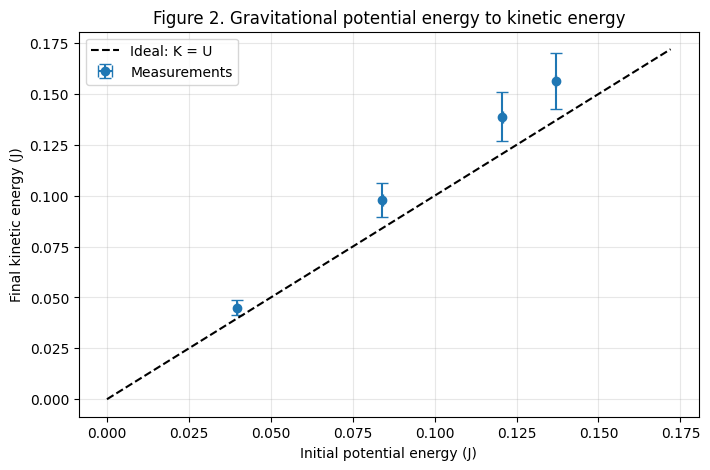

Diagnostic fit: Coefficients (from curve_fit)
[-6.86756865e-04  1.15791401e+00]
Diagnostic fit: Covariance Matrix (from curve_fit)
[[ 4.63573977e-05 -6.19315370e-04]
 [-6.19315370e-04  1.07260469e-02]]

Diagnostic fit: Final Result: y = (1.15791 +/- 0.10357) x + (-0.00069 +/- 0.00681)



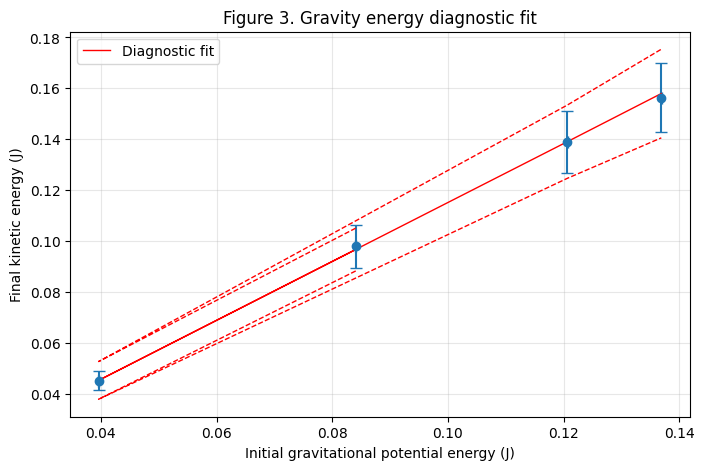

Slope = 1.15791 ± 0.104; ideal 1
Intercept = -0.000686757 ± 0.00681 J; ideal 0


In [14]:
gravity_table = energy_plot(
    {"Gravity 1":gravity_1, "Gravity 2":gravity_2, "Gravity 3":gravity_3, "Gravity 4":gravity_4},
    "Figure 2. Gravitational potential energy to kinetic energy")
# Diagnostic fit: vertical errors only; x errors and shared correlations are omitted.
plt.figure(figsize=(8, 5))
plt.errorbar(gravity_table["U (J)"], gravity_table["K (J)"],
             xerr=gravity_table["u_U (J)"], yerr=gravity_table["u_K (J)"], fmt="o", capsize=4)
b_g, slope_g, u_b_g, u_slope_g = p201.linear_fit_plot_errors(
    gravity_table["U (J)"].to_numpy(), gravity_table["K (J)"].to_numpy(),
    gravity_table["u_K (J)"].to_numpy(), plt, labelstring="Diagnostic fit")
plt.xlabel("Initial gravitational potential energy (J)")
plt.ylabel("Final kinetic energy (J)")
plt.title("Figure 3. Gravity energy diagnostic fit")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print(f"Slope = {slope_g:.6g} ± {u_slope_g:.3g}; ideal 1")
print(f"Intercept = {b_g:.6g} ± {u_b_g:.3g} J; ideal 0")

**Gravity checkpoint:** REPLACE WITH YOUR quantitative comparison of U and K for every configuration, predicted and measured speeds, fitted slope/intercept, uncertainty limitations, and evidence for energy transfer to the pulley, friction, or other unmodeled effects. Explain any apparatus changes made after checking the results.

# Part III — Spring potential energy to kinetic energy
Disconnect the string and hanger. Install the spring on the short launch rod with a secured bumper at the far end. Use the same calibrated spring. For **at least two distinct compressions**, within its linear calibration range and at least 1 cm, measure compression and release the cart quickly without an extra push. Measure the cart's complete moving mass. Collect **four launches per compression**.

Consider how reproducibly you set the compression and include this in its uncertainty. Measure speed after the cart has left the spring. Enter and analyze one configuration before moving to the next. Duplicate a configuration cell and add its result to the final plot if you collect more than two compressions.

## Spring configuration 1
Enter four launches and check the result before changing the compression.

In [ ]:
# REPLACE all examples with measurements for spring configuration 1.
m_cart = 0.18995     # kg; actual complete moving mass in spring setup
u_m_cart = 0.000005  # kg
x_s = 0.012            # m; compression relative to unloaded length
u_x_s = 0.0005       # m; include repeatability of setting the compression
speeds = [0.47, 0.48, 0.47, 0.49]        # m/s
if x_s < 0.01 or not compression.min() <= x_s <= compression.max():
    raise ValueError("Use at least 1 cm compression within the calibrated linear range")
spring_1 = spring_run(m_cart, u_m_cart, x_s, u_x_s, speeds)
show_result(spring_1)

,Trial,Speed (m/s)
0,1,0.47
1,2,0.48
2,3,0.47
3,4,0.49


Mean speed = 0.4775 ± 0.00571 m/s; s = 0.00957; SEM = 0.00479 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s),k_dynamic (N/m),u_k_dynamic (N/m)
0,0.0229834,0.00192745,0.0216549,0.000518005,0.0013285,0.00199584,0.665636,0.491929,0.0206272,300.762,26.0757


## Spring configuration 2
Enter four launches and check the result before changing the compression.

In [ ]:
# REPLACE all examples with measurements for spring configuration 2.
m_cart = 0.18995     # kg; actual complete moving mass in spring setup
u_m_cart = 0.000005  # kg
x_s = 0.018            # m; compression relative to unloaded length
u_x_s = 0.0005       # m; include repeatability of setting the compression
speeds = [0.71, 0.72, 0.7, 0.71]        # m/s
if x_s < 0.01 or not compression.min() <= x_s <= compression.max():
    raise ValueError("Use at least 1 cm compression within the calibrated linear range")
spring_2 = spring_run(m_cart, u_m_cart, x_s, u_x_s, speeds)
show_result(spring_2)

,Trial,Speed (m/s)
0,1,0.71
1,2,0.72
2,3,0.7
3,4,0.71


Mean speed = 0.71 ± 0.00577 m/s; s = 0.00816; SEM = 0.00408 m/s


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s),k_dynamic (N/m),u_k_dynamic (N/m)
0,0.0517126,0.00291382,0.0478769,0.000777892,0.00383575,0.00301587,1.27186,0.737894,0.0207888,295.536,17.1065


,U (J),u_U (J),K (J),u_K (J),D (J),u_D (J),D/u_D,v_pred (m/s),u_v_pred (m/s),k_dynamic (N/m),u_k_dynamic (N/m)
Spring 1,0.0229834,0.00192745,0.0216549,0.000518005,0.0013285,0.00199584,0.665636,0.491929,0.0206272,300.762,26.0757
Spring 2,0.0517126,0.00291382,0.0478769,0.000777892,0.00383575,0.00301587,1.27186,0.737894,0.0207888,295.536,17.1065


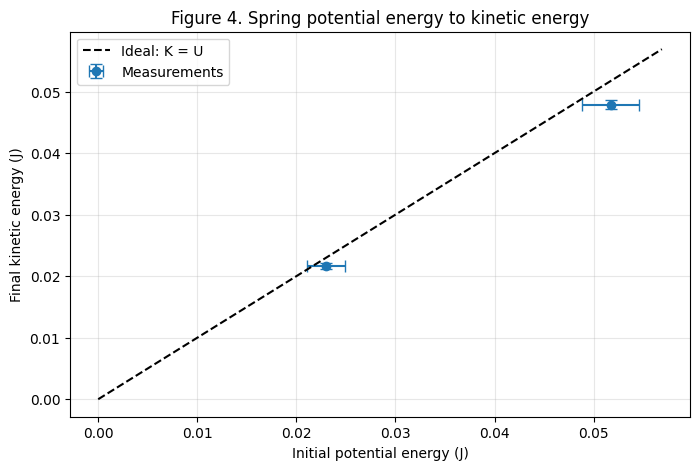

Static calibration: k = 319.214 ± 3 N/m
Compare each dynamic k with the static calibration; do not average correlated values blindly.


In [ ]:
spring_table = energy_plot({"Spring 1":spring_1, "Spring 2":spring_2},
                           "Figure 4. Spring potential energy to kinetic energy")
print(f"Static calibration: k = {k:.6g} ± {u_k:.3g} N/m")
print("Compare each dynamic k with the static calibration; do not average correlated values blindly.")

**Spring checkpoint:** REPLACE WITH YOUR quantitative comparison of initial and final energies, predicted and measured speeds, and the dynamic values $k_{\rm dynamic}=m_cv^2/x_s^2$ with the static calibration. Explain any shortfall in measured kinetic energy, uncertainty in compression, and the limits of treating spring energy as entirely transferred to the cart. Two points do not support a meaningful goodness-of-fit test for a free slope and intercept.

# Optional Part IV — Spring energy to gravitational potential energy
Only with instructor approval, remove the photogate and raise the far leg of the track on a secure wooden shim. Launch the cart uphill from the calibrated spring and determine the rise of its center of mass to the turning point. Decide whether direct height measurements or distance along the track and measured incline are more reliable.

If performed, add raw trial tables, uncertainties, a labeled apparatus diagram, and calculations comparing $\tfrac12kx_s^2$ with $m_cg\Delta y$. Explain how the incline changes gravitational energy while the cart remains in contact with the spring. Otherwise state that this optional part was not performed.

# Team report
Replace these prompts with a coherent report under the course notebook rubric.

## Experimental procedure
REPLACE WITH a reproducible account of the track leveling, spring calibration, photogate/flag setup, masses, drop/compression definitions, release technique, uncertainties, safety practices, and troubleshooting. Include a labeled setup diagram or photograph.

## Results and discussion
REPLACE WITH a quantitative discussion of all configurations, energy tables, figures, calibration and fit results with units and uncertainties. Explain whether discrepancies are consistent with the uncertainty model and which physical mechanisms could account for them. Distinguish evidence for an approximate mechanical-energy model from a claim that total energy is destroyed. Discuss shared calibration errors and limits of vertical-error-only fits. Explain the comparison of static and dynamic spring constants.

## Conclusions
REPLACE WITH your conclusions, the most consequential uncertainty or systematic effect, and specific improvements supported by your observations.

## Appendix and acknowledgment
REPLACE WITH signed raw-data sheets, sample energy and uncertainty calculations for one gravity and one spring configuration, the calibration measurements/Capstone graph, and acknowledgment of assistance that materially contributed to the work. Keep all raw trials, including excluded readings with reasons for exclusion.

# Submission checklist
- [ ] Replace team identification, all example measurements and uncertainty entries, and every written prompt.
- [ ] Preserve the spring calibration and four gravity configurations with four trials each; include at least two spring compressions with four trials each.
- [ ] Explain the calibration intercept, horizontal uncertainties, and adopted spring-constant uncertainty.
- [ ] Complete each checkpoint, the report, and appendices.
- [ ] Run **Runtime → Run all** and check every table and figure for errors, correct units, and consistency with team measurements.
- [ ] Save through **File → Save a copy in GitHub** to the team's fork using this notebook's original path.
- [ ] Verify on GitHub that the latest raw data, executed outputs, and writing are present.
- [ ] Submit one team notebook URL through Scholar by **November 2, 2026, at 8:45 p.m.**
- [ ] Each student separately submits their private Individual Team Effort Report through Scholar.